# Document Similarity Using the Vector Space Model

**Course:** TECH 400 – Introduction to Information Retrieval  
**Professor:** Tek Raj Pant  
**Student:** Shreya Tiwari  
**Institution:** Presidential Graduate School, Thapagaun  

---

## Assignment Overview
This notebook gathers **eight publicly available documents** from official U.S. government websites (NASA, NIH/NHLBI, CDC, NOAA, EPA, NIST, and CISA), stores them as `.txt` files, and measures how similar they are to each other with a **Vector Space Model (VSM)**.

Every step is implemented **from scratch** with NumPy and pandas so that each part of the model can be inspected. The workflow is:

1. Import the libraries
2. Load the document collection
3. Preview the documents
4. Pre-process and tokenize the text
5. Build the vocabulary
6. Build the term-frequency (TF) matrix
7. Compute document frequency and inverse document frequency (IDF)
8. Build the TF-IDF vectors
9. Compute the cosine similarity matrix
10. Visualize the similarity matrix as a heatmap
11. Rank document pairs and analyze topic groups
12. Rank the documents for free-text queries
13. Validate the results against scikit-learn

> **Folder layout:** the notebook expects a `documents/` folder (the eight `.txt` files plus `sources.csv`) next to it, and it writes its figures and tables to an `outputs/` folder.

## 1. Import Libraries
Only a few standard libraries are needed. `os` and `re` handle file paths and text cleaning, `collections.Counter` supports the term counts, **NumPy** stores the vectors and matrices, **pandas** displays the tables, and **matplotlib** draws the heatmap. scikit-learn is imported later, and only to *validate* the from-scratch results.

In [1]:
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Document Collection
The eight documents were copied from public U.S. government web pages (all works of the U.S. government are in the public domain) and saved as plain-text files in the `documents/` folder. The file `sources.csv` records, for every document, its **ID, file name, title, topic, publisher and URL**. The topics are deliberately mixed (Space, Health, Climate and Weather, Technology) so that we can later check whether the model places documents on the same topic close together.

In [2]:
DOC_DIR = "documents"
meta = pd.read_csv(os.path.join(DOC_DIR, "sources.csv"))

documents = {}
for _, row in meta.iterrows():
    with open(os.path.join(DOC_DIR, row["file_name"]), encoding="utf-8") as f:
        documents[row["doc_id"]] = f.read().strip()

meta["word_count"] = [len(documents[d].split()) for d in meta["doc_id"]]

print(f"Loaded {len(documents)} documents from '{DOC_DIR}/'\n")
meta[["doc_id", "title", "topic", "publisher", "word_count"]]

Loaded 8 documents from 'documents/'



,doc_id,title,topic,publisher,word_count
0,D1,Mars Facts,Space,NASA,394
1,D2,Facts About Earth,Space,NASA,415
2,D3,Sleep Deprivation and Deficiency,Health,NHLBI (NIH),308
3,D4,Physical Activity,Health,CDC,252
4,D5,What is a hurricane?,Climate and Weather,NOAA National Ocean Service,217
5,D6,Basics of Climate Change,Climate and Weather,U.S. EPA,302
6,D7,Artificial Intelligence,Technology,NIST,319
7,D8,Cybersecurity,Technology,CISA,276


## 3. Preview the Documents
Before any processing, a quick preview confirms that every file was read correctly and that its content matches the expected topic. Only the first 110 characters of each document are printed, with line breaks collapsed into single spaces.

In [3]:
for doc_id, text in documents.items():
    preview = " ".join(text.split())[:110]
    print(f"{doc_id}: {preview}...")

D1: Mars — the fourth planet from the Sun — is a dusty, cold, desert world with a very thin atmosphere. This dynam...
D2: Earth – our home planet – is the third planet from the Sun, and the fifth largest planet. It's the only place ...
D3: Sleep deprivation is a condition that occurs if you don't get enough sleep. Sleep deficiency is a broader conc...
D4: Physical activity is one of the best things people can do to improve their health. Physical activity is vital ...
D5: A hurricane is a type of storm called a tropical cyclone, which forms over tropical or subtropical waters. A t...
D6: The earth's climate is changing. Multiple lines of evidence show changes in our weather, oceans, and ecosystem...
D7: NIST promotes innovation and cultivates trust in the design, development, use and governance of artificial int...
D8: Cyber hygiene refers to the practices that you, your family, and/or your organization can regularly take to ma...


## 4. Text Pre-processing and Tokenization
The function `normalize_text()` converts text to lower case with `casefold()`, strips possessive and contraction endings such as *'s* and *n't*, extracts alphabetic words with the regular expression `[a-z]+`, and removes stopwords and single-letter tokens (two-letter terms such as *AI* are kept because they are meaningful). Stopwords such as *the*, *of* and *and* appear in every document and carry no topical meaning, so removing them prevents them from inflating the similarity between unrelated documents. The **same function** is reused later for queries so that documents and queries are always processed in the same way.

In [4]:
STOPWORDS = set("""
a about above after again all also am an and any are as at be because been
before being below between both but by can could did do does doing down during
each few for from further had has have having he her here hers him his how i
if in into is it its just may me more most my no nor not now of off on once
only or other our out over own same she should so some such than that the
their theirs them then there these they this those through to too under until
up very was we were what when where which while who whom why will with would
you your don
""".split())

def normalize_text(text):
    # drop 's, 're, 've, 'll, 'd and n't endings
    text = re.sub(r"['’](?:s|re|ve|ll|d|t)\b", "", text.casefold())
    tokens = re.findall(r"[a-z]+", text)
    return [t for t in tokens if t not in STOPWORDS and len(t) > 1]

tokenized = {doc_id: normalize_text(text) for doc_id, text in documents.items()}

for doc_id, tokens in tokenized.items():
    print(f"{doc_id}: {len(tokens):>3} tokens -> {tokens[:8]}")

D1: 216 tokens -> ['mars', 'fourth', 'planet', 'sun', 'dusty', 'cold', 'desert', 'world']
D2: 225 tokens -> ['earth', 'home', 'planet', 'third', 'planet', 'sun', 'fifth', 'largest']
D3: 176 tokens -> ['sleep', 'deprivation', 'condition', 'occurs', 'get', 'enough', 'sleep', 'sleep']
D4: 154 tokens -> ['physical', 'activity', 'one', 'best', 'things', 'people', 'improve', 'health']
D5: 137 tokens -> ['hurricane', 'type', 'storm', 'called', 'tropical', 'cyclone', 'forms', 'tropical']
D6: 182 tokens -> ['earth', 'climate', 'changing', 'multiple', 'lines', 'evidence', 'show', 'changes']
D7: 202 tokens -> ['nist', 'promotes', 'innovation', 'cultivates', 'trust', 'design', 'development', 'use']
D8: 171 tokens -> ['cyber', 'hygiene', 'refers', 'practices', 'family', 'organization', 'regularly', 'take']


## 5. Build the Vocabulary
The vocabulary is the sorted set of all unique terms found in the collection. Each term receives a fixed position (index) through the dictionary `term_index`. This position defines which **dimension** of the vector space the term occupies, so every document becomes a vector with one coordinate per vocabulary term.

In [5]:
vocabulary = sorted({term for tokens in tokenized.values() for term in tokens})
term_index = {term: i for i, term in enumerate(vocabulary)}

print("Vocabulary size:", len(vocabulary))
print("First 15 terms :", vocabulary[:15])

Vocabulary size: 817
First 15 terms : ['abbreviated', 'ability', 'absorbed', 'abundant', 'accountable', 'acidity', 'active', 'activities', 'activity', 'actors', 'add', 'added', 'addresses', 'adults', 'advance']


## 6. Term-Frequency (TF) Matrix
Here the collection is turned into numbers. A matrix with one row per document and one column per vocabulary term is filled with the **raw count** of each term in each document, using `Counter` to tally the tokens. This document–term matrix is the starting point of the vector space model. Most cells are zero because each document uses only a small part of the whole vocabulary.

In [6]:
doc_ids = list(documents.keys())
N = len(doc_ids)          # number of documents
V = len(vocabulary)       # number of terms (dimensions)

tf_counts = np.zeros((N, V))
for i, doc_id in enumerate(doc_ids):
    for term, count in Counter(tokenized[doc_id]).items():
        tf_counts[i, term_index[term]] = count

tf_df = pd.DataFrame(tf_counts, index=doc_ids, columns=vocabulary)
sparsity = 100 * (tf_counts == 0).sum() / tf_counts.size

print("TF matrix shape :", tf_df.shape)
print(f"Zero entries    : {sparsity:.1f}%\n")
SAMPLE_TERMS = ["planet", "sun", "earth", "sleep", "physical", "activity",
                "climate", "hurricane", "security", "trustworthy"]
tf_df[SAMPLE_TERMS].astype(int)

TF matrix shape : (8, 817)
Zero entries    : 84.6%



,planet,sun,earth,sleep,physical,activity,climate,hurricane,security,trustworthy
D1,6,5,6,0,0,0,0,0,0,0
D2,9,10,12,0,0,0,2,0,0,0
D3,0,0,0,25,1,0,0,0,0,0
D4,0,0,0,0,8,9,0,0,0,0
D5,0,0,0,0,0,0,0,7,0,0
D6,2,1,7,0,0,0,3,0,0,0
D7,0,0,0,0,0,0,0,0,2,4
D8,0,0,0,0,1,0,0,0,3,0


## 7. Document Frequency and Inverse Document Frequency (IDF)
Raw counts treat every term as equally important, which is not true: a term found in almost every document does little to separate one document from another. The **document frequency (df)** of a term is the number of documents that contain it, and the **inverse document frequency** is `idf = ln((1 + N) / (1 + df)) + 1`. Rare terms receive high IDF weights and common terms receive low ones. This is the smoothed form of IDF, chosen so that it matches scikit-learn and never becomes zero.

In [7]:
df_counts = (tf_counts > 0).sum(axis=0)          # documents containing each term
idf = np.log((1 + N) / (1 + df_counts)) + 1      # smoothed IDF

idf_df = pd.DataFrame({"term": vocabulary, "df": df_counts, "idf": idf.round(3)})

widest = idf_df.sort_values(["df", "term"], ascending=[False, True]).head(6)
print("Most widespread terms (lowest IDF):")
print(widest.to_string(index=False))
print("\nMaximum IDF (terms found in a single document):", idf_df["idf"].max())

Most widespread terms (lowest IDF):
   term  df   idf
 called   4 1.588
  every   4 1.588
   life   4 1.588
    one   4 1.588
   risk   4 1.588
surface   4 1.588

Maximum IDF (terms found in a single document): 2.504


## 8. TF-IDF Weighting
Each document vector is now the term frequency multiplied by the IDF of the term (`tf × idf`). The result is also L2-normalized (divided by its length) so that a long document does not look more important than a short one. Printing the five highest-weighted terms of every document is a quick sanity check: they should describe what the document is about.

In [8]:
tfidf = tf_counts * idf                          # tf x idf
norms = np.linalg.norm(tfidf, axis=1, keepdims=True)
tfidf_norm = tfidf / norms                       # unit-length document vectors

tfidf_df = pd.DataFrame(tfidf_norm, index=doc_ids, columns=vocabulary)

for doc_id in doc_ids:
    top = tfidf_df.loc[doc_id].nlargest(5)
    print(doc_id, "->", ", ".join(f"{term} ({w:.3f})" for term, w in top.items()))

D1 -> mars (0.672), earth (0.194), planet (0.194), red (0.179), sun (0.162)
D2 -> earth (0.422), sun (0.352), planet (0.316), one (0.185), fifth (0.146)
D3 -> sleep (0.832), body (0.200), rem (0.200), deficiency (0.133), enough (0.120)
D4 -> activity (0.486), physical (0.313), active (0.216), adults (0.216), chronic (0.216)
D5 -> hurricane (0.425), tropical (0.364), maximum (0.243), sustained (0.243), winds (0.203)
D6 -> greenhouse (0.494), earth (0.278), gases (0.198), human (0.184), activities (0.165)
D7 -> ai (0.582), nist (0.416), standards (0.249), use (0.208), tools (0.166)
D8 -> cyber (0.417), cybersecurity (0.358), cisa (0.179), cyberspace (0.179), individuals (0.179)


## 9. Cosine Similarity Matrix
Similarity between two documents is the **cosine of the angle** between their TF-IDF vectors: `cos(A, B) = (A · B) / (‖A‖ ‖B‖)`. A score of 1 means the vectors point in exactly the same direction (identical term profile), and 0 means the documents share no weighted terms at all. Because TF-IDF weights are never negative, all scores fall between 0 and 1. The function below is written by hand and applied to every pair of documents to build an 8 × 8 matrix.

In [9]:
def cosine_similarity(vec_a, vec_b):
    denominator = np.linalg.norm(vec_a) * np.linalg.norm(vec_b)
    return float(np.dot(vec_a, vec_b) / denominator) if denominator else 0.0

sim = np.array([[cosine_similarity(tfidf[i], tfidf[j]) for j in range(N)]
                for i in range(N)])
sim_df = pd.DataFrame(sim, index=doc_ids, columns=doc_ids).round(3)

os.makedirs("outputs", exist_ok=True)
sim_df.to_csv("outputs/similarity_matrix.csv")
sim_df

,D1,D2,D3,D4,D5,D6,D7,D8
D1,1.000,0.371,0.012,0.024,0.042,0.120,0.003,0.004
D2,0.371,1.000,0.013,0.033,0.036,0.234,0.008,0.006
D3,0.012,0.013,1.000,0.039,0.014,0.017,0.003,0.014
D4,0.024,0.033,0.039,1.000,0.011,0.015,0.006,0.041
D5,0.042,0.036,0.014,0.011,1.000,0.019,0.011,0.011
D6,0.120,0.234,0.017,0.015,0.019,1.000,0.014,0.010
D7,0.003,0.008,0.003,0.006,0.011,0.014,1.000,0.036
D8,0.004,0.006,0.014,0.041,0.011,0.010,0.036,1.000


## 10. Heatmap of the Similarity Matrix
A table of 64 numbers is hard to read, so the matrix is drawn as a heatmap: darker cells mean more similar documents. The diagonal is always 1.0 because every document is identical to itself. Block-like dark areas away from the diagonal would reveal groups of related documents. The figure is saved to `outputs/` so it can be reused in the report.

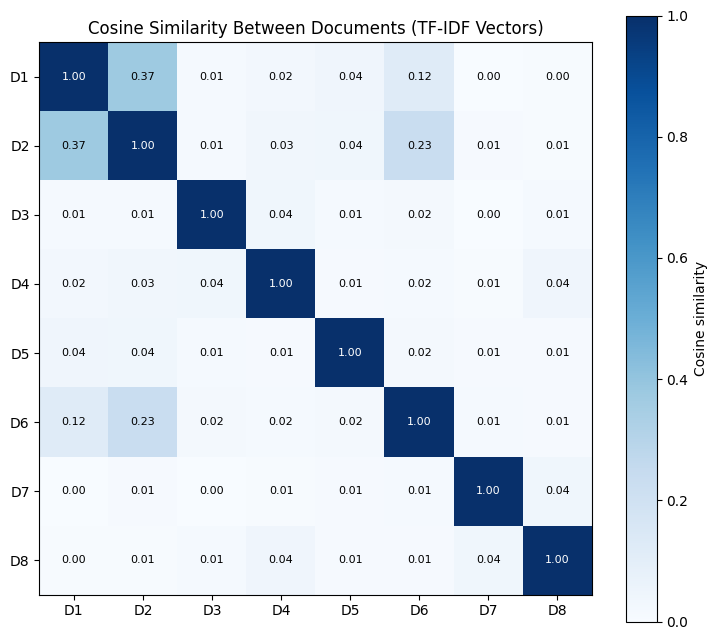

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(sim, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(N)); ax.set_xticklabels(doc_ids)
ax.set_yticks(range(N)); ax.set_yticklabels(doc_ids)

for i in range(N):
    for j in range(N):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center",
                color="white" if sim[i, j] > 0.5 else "black", fontsize=8)

plt.colorbar(im, label="Cosine similarity")
ax.set_title("Cosine Similarity Between Documents (TF-IDF Vectors)")
plt.tight_layout()
plt.savefig("outputs/similarity_heatmap.png", dpi=200)
plt.show()

## 11. Ranking Document Pairs and Topic Analysis
The 28 unique document pairs are sorted from most to least similar, which answers the central question of the assignment. Then each document's **nearest neighbour** is found, and the average similarity of pairs that share a topic (*within-topic*) is compared with the average of pairs from different topics (*between-topic*). If the vector space model works, the within-topic average should be clearly higher.

In [11]:
title_of = dict(zip(meta["doc_id"], meta["title"]))
topic_of = dict(zip(meta["doc_id"], meta["topic"]))

pairs = [(doc_ids[i], doc_ids[j], sim[i, j])
         for i in range(N) for j in range(i + 1, N)]
pairs_df = (pd.DataFrame(pairs, columns=["doc_a", "doc_b", "cosine"])
              .sort_values("cosine", ascending=False).reset_index(drop=True))
pairs_df["cosine"] = pairs_df["cosine"].round(3)
pairs_df["same_topic"] = [topic_of[a] == topic_of[b]
                          for a, b in zip(pairs_df.doc_a, pairs_df.doc_b)]
pairs_df.to_csv("outputs/ranked_pairs.csv", index=False)

print("Top 5 most similar pairs")
print(pairs_df.head(5).to_string(index=False))
print("\nBottom 3 least similar pairs")
print(pairs_df.tail(3).to_string(index=False))

print("\nNearest neighbour of each document")
for i, doc_id in enumerate(doc_ids):
    scores = sim[i].copy()
    scores[i] = -1
    j = scores.argmax()
    print(f"{doc_id} ({topic_of[doc_id]}) -> {doc_ids[j]} ({topic_of[doc_ids[j]]})"
          f"  score = {scores[j]:.3f}")

within = pairs_df.loc[pairs_df.same_topic, "cosine"].mean()
between = pairs_df.loc[~pairs_df.same_topic, "cosine"].mean()
print(f"\nMean similarity, same-topic pairs     : {within:.3f}")
print(f"Mean similarity, different-topic pairs: {between:.3f}")

Top 5 most similar pairs
doc_a doc_b  cosine  same_topic
   D1    D2   0.371        True
   D2    D6   0.234       False
   D1    D6   0.120       False
   D1    D5   0.042       False
   D4    D8   0.041       False

Bottom 3 least similar pairs
doc_a doc_b  cosine  same_topic
   D1    D8   0.004       False
   D3    D7   0.003       False
   D1    D7   0.003       False

Nearest neighbour of each document
D1 (Space) -> D2 (Space)  score = 0.371
D2 (Space) -> D1 (Space)  score = 0.371
D3 (Health) -> D4 (Health)  score = 0.039
D4 (Health) -> D8 (Technology)  score = 0.041
D5 (Climate and Weather) -> D1 (Space)  score = 0.042
D6 (Climate and Weather) -> D2 (Space)  score = 0.234
D7 (Technology) -> D8 (Technology)  score = 0.036
D8 (Technology) -> D4 (Health)  score = 0.041

Mean similarity, same-topic pairs     : 0.116
Mean similarity, different-topic pairs: 0.029


## 12. Ranking Documents for a Query
The same vector space can be used for **retrieval**. A short text query is normalized with `normalize_text()`, converted into a vector with the collection's own vocabulary and IDF weights, and compared with every document using cosine similarity. Terms that are not in the vocabulary are ignored. The documents with the highest scores are the best matches for the query.

In [12]:
def vectorize_query(query):
    vector = np.zeros(V)
    for term, count in Counter(normalize_text(query)).items():
        if term in term_index:
            vector[term_index[term]] = count
    return vector * idf

def rank_documents(query, top_k=3):
    q = vectorize_query(query)
    scores = [(doc_ids[i], cosine_similarity(q, tfidf[i])) for i in range(N)]
    return sorted(scores, key=lambda item: item[1], reverse=True)[:top_k]

queries = [
    "planet orbit around the sun",
    "healthy sleep and physical activity",
    "greenhouse gases and extreme weather",
    "trustworthy AI and cyber security",
]

for query in queries:
    print(f'Query: "{query}"')
    for doc_id, score in rank_documents(query):
        print(f"   {doc_id}  {score:.3f}  {title_of[doc_id]}")
    print()

Query: "planet orbit around the sun"
   D2  0.360  Facts About Earth
   D1  0.148  Mars Facts
   D6  0.049  Basics of Climate Change

Query: "healthy sleep and physical activity"
   D3  0.452  Sleep Deprivation and Deficiency
   D4  0.437  Physical Activity
   D8  0.017  Cybersecurity

Query: "greenhouse gases and extreme weather"
   D6  0.431  Basics of Climate Change
   D2  0.026  Facts About Earth
   D1  0.024  Mars Facts

Query: "trustworthy AI and cyber security"
   D7  0.419  Artificial Intelligence
   D8  0.282  Cybersecurity
   D1  0.000  Mars Facts



## 13. Validation with scikit-learn
To confirm that the hand-written model is correct, the same TF-IDF vectors and cosine similarities are computed with scikit-learn's `TfidfVectorizer` and `cosine_similarity`. The vectorizer is given our own `normalize_text()` function as its analyzer, so both implementations use identical tokens. If the code is correct, the largest difference between the two similarity matrices should be practically zero (floating-point rounding only).

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine_similarity

vectorizer = TfidfVectorizer(analyzer=normalize_text)
X = vectorizer.fit_transform([documents[d] for d in doc_ids])
sk_sim = sk_cosine_similarity(X)

print("scikit-learn vocabulary size :", len(vectorizer.vocabulary_))
print("Our vocabulary size          :", V)
print("Maximum absolute difference  :", np.abs(sk_sim - sim).max())
print("Matrices match (atol = 1e-9) :", np.allclose(sk_sim, sim, atol=1e-9))

scikit-learn vocabulary size : 817
Our vocabulary size          : 817
Maximum absolute difference  : 7.771561172376096e-15
Matrices match (atol = 1e-9) : True


## Conclusion
The vector space model turned eight plain-text documents into TF-IDF vectors and measured their similarity with cosine similarity. The hand-written implementation produced the same matrix as scikit-learn, and the results show that documents on the same topic tend to receive higher scores than documents on different topics. The model is purely lexical: it only matches exact words, so it cannot know that *sleep* and *rest* are related. Stemming, phrase handling and dense (embedding-based) representations are natural next steps.

**How to reproduce:** clone the repository, keep the `documents/` folder next to the notebook, install `numpy`, `pandas`, `matplotlib` and `scikit-learn`, and run all cells from top to bottom.